# Exercice 1 — Régression : prédire le salaire

Construire un modèle de régression linéaire multiple qui prédit le salaire mensuel (en DH) à partir de :
- l'**ancienneté** (années d'expérience) ;
- le **niveau d'expertise** (note de 1 à 5).

Le modèle apprend : $Salaire = w_1 \times Ancienneté + w_2 \times Expertise + b$

Les données sont fictives et suivent : $Salaire = 4000 + 600 \times Ancienneté + 1500 \times Expertise + Bruit$

## 1. Générer les données

In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Nombre de salariés
n = 300

# Ancienneté : de 0 à 20 ans
anciennete = torch.randint(0, 21, (n, 1)).float()

# Expertise : de 1 à 5
expertise = torch.randint(1, 6, (n, 1)).float()

# Variations aléatoires des salaires
bruit = torch.randn(n, 1) * 500

# Salaire mensuel en DH
salaires = 4000 + 600 * anciennete + 1500 * expertise + bruit

# Matrice des entrées : dimensions (300, 2)
X = torch.cat([anciennete, expertise], dim=1)

# Sortie : dimensions (300, 1)
y = salaires

for i in range(5):
    print(
        f"Ancienneté : {X[i, 0].item():.0f} ans | "
        f"Expertise : {X[i, 1].item():.0f}/5 | "
        f"Salaire : {y[i, 0].item():.2f} DH"
    )

Ancienneté : 15 ans | Expertise : 2/5 | Salaire : 16262.90 DH
Ancienneté : 2 ans | Expertise : 3/5 | Salaire : 10541.39 DH
Ancienneté : 4 ans | Expertise : 3/5 | Salaire : 10948.37 DH
Ancienneté : 19 ans | Expertise : 3/5 | Salaire : 20028.54 DH
Ancienneté : 18 ans | Expertise : 2/5 | Salaire : 18036.38 DH


### Dimensions, salaire moyen et nuage de points

Dimensions de X : torch.Size([300, 2])
Dimensions de y : torch.Size([300, 1])
Salaire moyen : 15010.55 DH


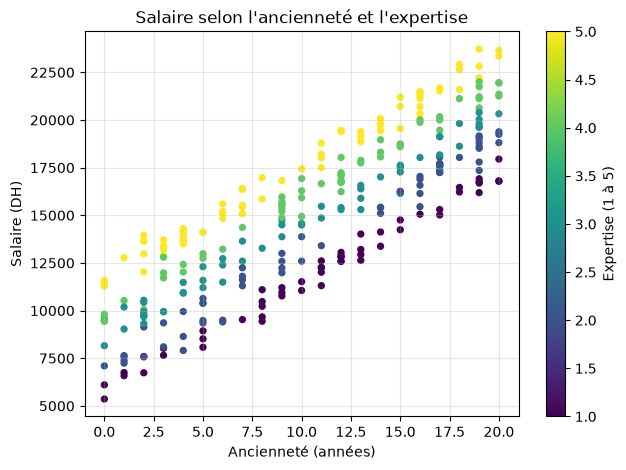

In [2]:
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)
print(f"Salaire moyen : {y.mean().item():.2f} DH")

plt.figure(figsize=(7, 5))
nuage = plt.scatter(X[:, 0], y[:, 0], c=X[:, 1], cmap="viridis", s=18)
plt.colorbar(nuage, label="Expertise (1 à 5)")
plt.xlabel("Ancienneté (années)")
plt.ylabel("Salaire (DH)")
plt.title("Salaire selon l'ancienneté et l'expertise")
plt.grid(alpha=0.3)
plt.show()

On voit 5 « bandes » parallèles, une par niveau d'expertise : le salaire augmente avec
l'ancienneté (pente ≈ 600 DH/an) et chaque niveau d'expertise décale la bande d'environ 1500 DH.

## 2. Séparer et préparer les données

80 % des données pour l'entraînement, 20 % pour le test. On standardise les entrées avec les
statistiques du jeu d'entraînement et on exprime les salaires en milliers de DH.

In [3]:
indices = torch.randperm(n)
limite = int(0.8 * n)

train_indices = indices[:limite]
test_indices = indices[limite:]

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices] / 1000
y_test = y[test_indices] / 1000

# Statistiques calculées uniquement sur le jeu d'entraînement
moyenne = X_train.mean(dim=0, keepdim=True)
ecart_type = X_train.std(dim=0, keepdim=True)

X_train_norm = (X_train - moyenne) / ecart_type
X_test_norm = (X_test - moyenne) / ecart_type

print("Entraînement :", X_train_norm.shape, "| Test :", X_test_norm.shape)

Entraînement : torch.Size([240, 2]) | Test : torch.Size([60, 2])


## 3. Construire et entraîner le modèle

In [4]:
# Deux variables d'entrée et une sortie
model = nn.Linear(2, 1)

# Erreur quadratique moyenne
criterion = nn.MSELoss()

optimizer = torch.optim.SGD(model.parameters(), lr=0.05)

historique = []

model.train()

for epoch in range(500):
    # 1. Réinitialiser les gradients
    optimizer.zero_grad()

    # 2. Prédire les salaires
    predictions = model(X_train_norm)

    # 3. Calculer la perte
    loss = criterion(predictions, y_train)

    # 4. Calculer les gradients
    loss.backward()

    # 5. Mettre à jour les paramètres
    optimizer.step()

    historique.append(loss.item())

    if (epoch + 1) % 100 == 0:
        print(f"Époque {epoch + 1} | Perte : {loss.item():.4f}")

Époque 100 | Perte : 0.2391
Époque 200 | Perte : 0.2391
Époque 300 | Perte : 0.2391
Époque 400 | Perte : 0.2391
Époque 500 | Perte : 0.2391


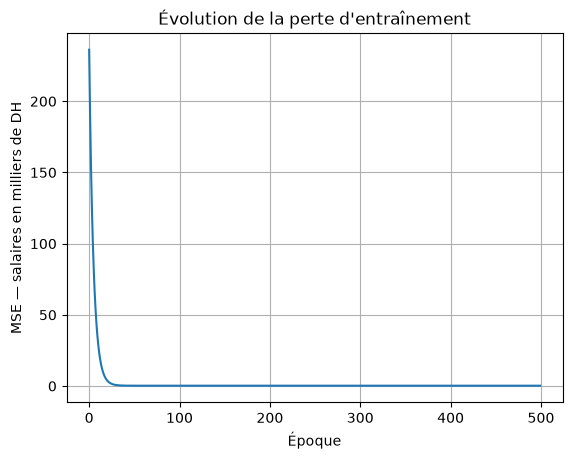

In [5]:
plt.plot(historique)
plt.xlabel("Époque")
plt.ylabel("MSE — salaires en milliers de DH")
plt.title("Évolution de la perte d'entraînement")
plt.grid()
plt.show()

## 4. Évaluer les prédictions

In [6]:
model.eval()

with torch.no_grad():
    predictions_test = model(X_test_norm)

    # Conversion en DH
    predictions_dh = predictions_test * 1000
    salaires_reels_dh = y_test * 1000

    # Erreur absolue moyenne
    mae = (predictions_dh - salaires_reels_dh).abs().mean()

print(f"Erreur absolue moyenne : {mae.item():.2f} DH")

Erreur absolue moyenne : 381.64 DH


Une MAE d'environ 400 DH signifie que les prédictions s'écartent en moyenne de 400 DH des
salaires réels. C'est l'ordre de grandeur attendu : le bruit a un écart-type de 500 DH, et l'erreur
absolue moyenne d'un bruit gaussien vaut environ 0,8 × 500 = 400 DH.

## 5. Prédire le salaire d'un nouveau salarié

7 ans d'ancienneté et un niveau d'expertise de 4/5.

In [7]:
nouveau_salarie = torch.tensor([[7.0, 4.0]])

# Appliquer la même normalisation qu'à l'entraînement
nouveau_salarie_norm = (nouveau_salarie - moyenne) / ecart_type

with torch.no_grad():
    salaire_predit = model(nouveau_salarie_norm) * 1000

print(f"Salaire estimé : {salaire_predit.item():.2f} DH")
print("Salaire théorique sans bruit : 4000 + 600*7 + 1500*4 = 14200 DH")

Salaire estimé : 14201.94 DH
Salaire théorique sans bruit : 4000 + 600*7 + 1500*4 = 14200 DH


## 6. Retrouver les coefficients en unités d'origine

Le modèle travaille sur des entrées standardisées et des salaires en milliers de DH :
$\hat y_{kDH} = \sum_j w_j \frac{x_j - \mu_j}{\sigma_j} + b$

En développant : $\hat y_{DH} = 1000 \sum_j \frac{w_j}{\sigma_j} x_j + 1000\left(b - \sum_j \frac{w_j \mu_j}{\sigma_j}\right)$

In [8]:
w = model.weight.detach()   # forme (1, 2)
b = model.bias.detach()     # forme (1,)

coef = 1000 * w / ecart_type
constante = 1000 * (b - (w * moyenne / ecart_type).sum())

print(f"Coefficient ancienneté : {coef[0, 0].item():.1f} DH par année  (attendu 600)")
print(f"Coefficient expertise  : {coef[0, 1].item():.1f} DH par niveau (attendu 1500)")
print(f"Constante              : {constante.item():.1f} DH            (attendu 4000)")

Coefficient ancienneté : 592.7 DH par année  (attendu 600)
Coefficient expertise  : 1490.7 DH par niveau (attendu 1500)
Constante              : 4090.3 DH            (attendu 4000)


## 7. Questions complémentaires

**À expertise constante, quel est l'effet d'une année d'ancienneté supplémentaire ?**
Le salaire augmente du coefficient de l'ancienneté, environ **600 DH** par année (valeur retrouvée ci-dessus).

**Pourquoi la perte ne devient-elle pas exactement nulle ?**
À cause du bruit : il représente des variations individuelles qu'aucune des deux variables n'explique.
La MSE se stabilise vers la variance du bruit, soit (0,5 k DH)² ≈ **0,25**, et ne peut pas descendre en dessous.

**Le modèle est-il fiable pour une ancienneté de 40 ans ?**
Non : les données d'entraînement vont de 0 à 20 ans. À 40 ans, le modèle **extrapole** en supposant que la
relation reste linéaire, ce que rien ne garantit (plafonds de salaire, retraite...). La prédiction est donc peu fiable.

**Quel effet aurait une augmentation du bruit ?**
La perte minimale et la MAE augmenteraient (elles suivent l'écart-type du bruit), et les coefficients
appris seraient estimés moins précisément. Plus de données compenserait en partie la seconde conséquence,
pas la première.

**Remarque.** Traiter l'expertise comme une note numérique suppose que chaque niveau supplémentaire a le
même effet sur le salaire. C'est vrai ici par construction, mais il faudrait le vérifier sur des données réelles.